<a href="https://colab.research.google.com/github/ambaralmaraz73/Solving-Job-Shop-Scheduling-via-Search-Heuristics-and-Local-Search-/blob/main/JSSP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

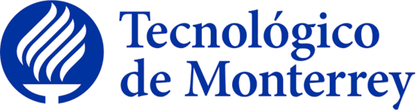

#**JOB-SHOP SCHEDULING PROBLEM**

##1-Problem definition and Gantt Diagram of initial state

Gantt chart successfully saved in: results/JSSP_Gantt_Chart.png


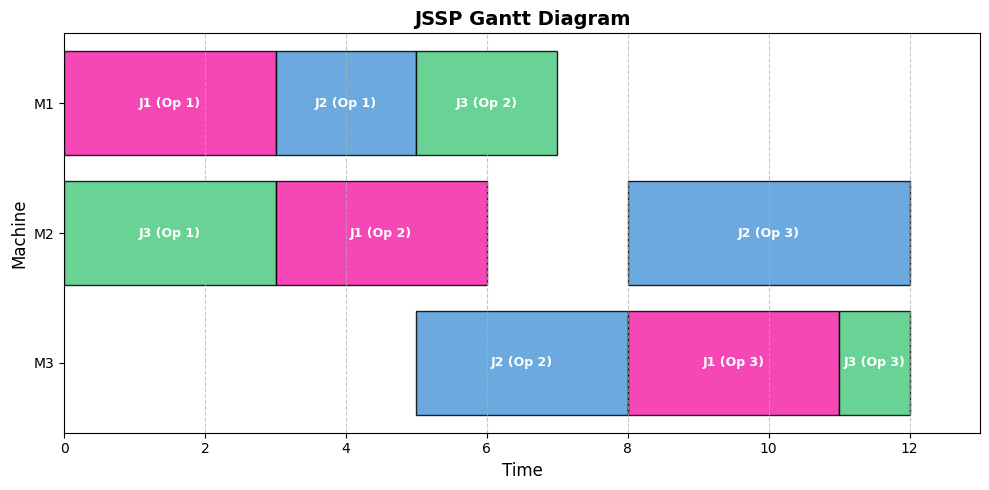

In [ ]:
import matplotlib.pyplot as plt
import os

data = [
    # Machine, Job, Initial time, Duration, Color
    ("M1", "J1 (Op 1)", 0, 3, '#F527A9'), # J1 (Pink)
    ("M1", "J2 (Op 1)", 3, 2, '#529AD9'), # J2 (Blue)
    ("M1", "J3 (Op 2)", 5, 2, '#4ECC81'), # J3 (Green)

    ("M2", "J3 (Op 1)", 0, 3, '#4ECC81'), # J3 (Green)
    ("M2", "J1 (Op 2)", 3, 3, '#F527A9'), # J1 (Pink)
    ("M2", "J2 (Op 3)", 8, 4, '#529AD9'), # J2 (Blue)

    ("M3", "J2 (Op 2)", 5, 3, '#529AD9'), # J2 (Blue)
    ("M3", "J1 (Op 3)", 8, 3, '#F527A9'), # J1 (Pink)
    ("M3", "J3 (Op 3)", 11, 1, '#4ECC81') # J3 (Green)
]

JOBS = {
    'J1': [('M1', 3), ('M2', 3), ('M3', 3)],  # Operations of Job 1
    'J2': [('M1', 2), ('M3', 3), ('M2', 4)],  # Operations of Job 2
    'J3': [('M2', 3), ('M1', 2), ('M3', 1)]   # Operations of Job 3
}

# Figure configuration
fig, ax = plt.subplots(figsize=(10, 5))

# Gantt Diagram
for machine, label, start, duration, color in data:
    ax.barh(machine, duration, left=start, color=color, edgecolor='black', alpha=0.85)

    # Operation description inside the bars
    ax.text(start + duration / 2, machine, label,
            ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# Axis and design
ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel('Machine', fontsize=12)
ax.set_title('JSSP Gantt Diagram', fontsize=14, fontweight='bold')

# Axis inversion, for the order of M1, M2 and M3
ax.invert_yaxis()

# Grid for lecture
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Axis limits (from 0 to the makespan 12 + margin)
ax.set_xlim(0, 13)

plt.tight_layout()

# Save the Gantt chart in the results folder
os.makedirs('results', exist_ok=True)
plt.savefig('results/JSSP_Gantt_Chart.png', dpi=300, bbox_inches='tight')
print("Gantt chart successfully saved in: results/JSSP_Gantt_Chart.png")

plt.show()

##2-Solving the problem

###2.1-"Depth-First Search"

In [ ]:
import time  # To control the 60 seconds limit

# Definition of the Jobs J per Machine M
# Each Job is a dictionary with a list of tuples: machine, duration

def dfs_jssp(time_limit=60.0):
    # Function to execute DFS to solve the JSSP with time limit
    # Registers the exact time to start the execution of the algorithm
    start_time_global = time.time()
    # Starts a bool in False to detect if exceeds the time limit
    timeout_reached = False
    t_best = None # Variable to track the exact time the best solution is found

    # Initial state to be placed on the search stack
    initial_state = {
        'progress': {'J1': 0, 'J2': 0, 'J3': 0},       # Track the index of the next pending operation for each job
        'machine_free': {'M1': 0, 'M2': 0, 'M3': 0},   # Track the time when each machine is not occupied
        'job_free': {'J1': 0, 'J2': 0, 'J3': 0},       # Track the time when each job completes its last executed operation
        'schedule': []                                 # Cumulative schedule list with assigned operations
    }

    stack = [initial_state]             # Initiates the stack of the DFS with the initial state (LIFO)
    best_makespan = float('inf')        # Initiates the best makespan in infinite to make sure that the first solution replaces it
    best_schedule = None                # Variable to store the best schedule sequence found

    # Metrics
    expanded_nodes = 0
    max_frontier_size = len(stack)

    while stack:                        # Main cycle of search while there are nodes in the stack
        # Track the maximum size that the stack reaches in memory
        max_frontier_size = max(max_frontier_size, len(stack))

        # Verifies if the current time minus the initial time exceeds the 60 secs limit
        if (time.time() - start_time_global) > time_limit:
            timeout_reached = True      # Changes to True indicating that the time budget has been reached
            break                       # Breaks and interrupts the search cycle

        current = stack.pop()           # Extracts and removes the last stack element (key operation of LIFO in DFS)
        expanded_nodes += 1             # Increment the counter every time a node is expanded

        # Goal test: verifies whether all jobs have completed the total number of their assigned operations
        if all(current['progress'][job] == len(JOBS[job]) for job in JOBS):
            makespan = max(current['machine_free'].values())  # Calculates the makespan determining the maximum release time of the machines
            if makespan < best_makespan:                      # If the current makespan is less than the previous one:
                best_makespan = makespan                      # Updates the best global makespan
                best_schedule = current['schedule']           # Saves the new optimal schedule
                t_best = time.time() - start_time_global      # Updates the exact time to best solution
            continue                                          # Continues to the next element on the stack

        # Generates available operations (successors / tree ramification)
        for job_id, ops in JOBS.items():                      # Iterates through each job and its respective operations
            step = current['progress'][job_id]                # Obtains the index of the current job operation
            if step < len(ops):                               # If the job still has pending operations to process:
                machine, duration = ops[step]                 # Extract the required machine and the duration of that operation

                # Calculation of the initial time:
                # It is the maximum value between the moment the machine is empty and the moment the job's previous operation finishes
                start_time = max(current['machine_free'][machine], current['job_free'][job_id])
                end_time = start_time + duration              # Calculates the exact time when the operation will conclude

                # Pruning / bounds check
                '''
                If the completion time of this operation is greater than or equal
                to the current best makespan, prune (skip) this branch.
                '''
                if end_time >= best_makespan:
                    continue

                # Copying and updating of state dictionaries for the successor node
                new_progress = current['progress'].copy()     # Copy the job progress dictionary
                new_progress[job_id] += 1                     # Increments the index of the processed job operation by 1

                new_machine_free = current['machine_free'].copy() # Copy the availability status of the machines
                new_machine_free[machine] = end_time              # Updates the release time of the machine used

                new_job_free = current['job_free'].copy()     # Copy the availability status of the jobs
                new_job_free[job_id] = end_time               # Updates the time when the job has finished

                # Create the new schedule by adding the currently scheduled operation
                new_schedule = current['schedule'] + [{
                    'Machine': machine,
                    'Label': f"{job_id} (Op {step + 1})",
                    'Initial time': start_time,
                    'Duration': duration
                }]

                # Insert the new successor state into the stack so that it can be explored later
                stack.append({
                    'progress': new_progress,
                    'machine_free': new_machine_free,
                    'job_free': new_job_free,
                    'schedule': new_schedule
                })

    elapsed_time = time.time() - start_time_global            # Calculates the total time elapsed during the execution

    return best_makespan, best_schedule, elapsed_time, t_best, timeout_reached, expanded_nodes, max_frontier_size

# Execution of the DFS algorithm calling the function with the 60 secs limit
optimal_makespan_dfs, optimal_schedule_dfs, time_dfs, t_best_dfs, timed_out_dfs, nodes_dfs, mem_dfs = dfs_jssp(time_limit=60.0)

# Success rate calculation (100% if a valid solution/makespan was found, 0% otherwise)
success_rate_dfs = 100.0 if (optimal_makespan_dfs != float('inf')) else 0.0

# Print results
print(f"Depht-First Search Results:")
print(f"Best makespan found: {optimal_makespan_dfs}" if optimal_makespan_dfs != float('inf') else "Best makespan found: N/A")
print(f"Execution time: {time_dfs:.4f} seconds")
print(f"Time to best solution: {t_best_dfs:.4f} seconds" if t_best_dfs is not None else "Time to best solution: N/A")
print(f"Success rate: {success_rate_dfs:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_dfs}")
print(f"Max frontier size (Memory): {mem_dfs}")
if timed_out_dfs:
    print("Notice: The 60-second time limit has been reached")

print("\nOptimal sequence of operations:")
if optimal_schedule_dfs:                 # If a valid schedule was found:
    for item in optimal_schedule_dfs:    # Go through each operation recorded in the schedule
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("No schedule was found within the time limit.")

Depht-First Search Results:
Best makespan found: 12
Execution time: 0.0085 seconds
Time to best solution: 0.0018 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 1263
Max frontier size (Memory): 10

Optimal sequence of operations:
Machine: M2 | J3 (Op 1) | Start: 0 | Duration: 3
Machine: M1 | J2 (Op 1) | Start: 0 | Duration: 2
Machine: M3 | J2 (Op 2) | Start: 2 | Duration: 3
Machine: M1 | J1 (Op 1) | Start: 2 | Duration: 3
Machine: M1 | J3 (Op 2) | Start: 5 | Duration: 2
Machine: M3 | J3 (Op 3) | Start: 7 | Duration: 1
Machine: M2 | J1 (Op 2) | Start: 5 | Duration: 3
Machine: M2 | J2 (Op 3) | Start: 8 | Duration: 4
Machine: M3 | J1 (Op 3) | Start: 8 | Duration: 3


###2.2-"A* Search" using two Heuristics: H1 and H2

In [ ]:
import time
import heapq

# Definition of the Jobs J per Machine M
# Each Job is a dictionary with a list of tuples: machine, duration

def heuristic(progress, h_type="H1"):
    """
    Calculates the admissible heuristic h(n) for the A* search.
    H1 (Cheap): Max remaining processing time among all jobs. Fast but less informative.
    H2 (More informative): Max of H1 and the remaining workload among all machines.
    """

    # H1: Maximum Remaining Job Time
    # Calculates the time required to finish the remaining operations for each job.
    max_job_remaining = 0
    for job_id, ops in JOBS.items():
        step = progress[job_id]                               # Current operation index for this job
        remaining_time = sum(duration for _, duration in ops[step:])
        max_job_remaining = max(max_job_remaining, remaining_time)

    if h_type == "H1":
        return max_job_remaining

    # H2: Maximum Machine Workload
    # Calculates the total processing time pending for each machine.
    # This is more informative because it accounts for machine bottlenecks.
    machine_workload = {'M1': 0, 'M2': 0, 'M3': 0}
    for job_id, ops in JOBS.items():
        step = progress[job_id]
        for machine, duration in ops[step:]:
            machine_workload[machine] += duration

    max_machine_remaining = max(machine_workload.values())

    # Returns the most pessimistic (highest) lower bound, which guarantees admissibility.
    return max(max_job_remaining, max_machine_remaining)

def a_star_jssp(h_type="H1", time_limit=60.0):
    start_time_global = time.time()
    timeout_reached = False
    time_to_best = None                                       # Initialize the variable to None to record the exact moment the best solution is found.

    # Initial state representation using dictionaries for fast O(1) lookups
    initial_state = {
        'progress': {'J1': 0, 'J2': 0, 'J3': 0},
        'machine_free': {'M1': 0, 'M2': 0, 'M3': 0},
        'job_free': {'J1': 0, 'J2': 0, 'J3': 0},
        'schedule': []
    }

    # g(n) is the cost to reach the current node. Initially 0.
    g_initial = 0
    h_initial = heuristic(initial_state['progress'], h_type)
    f_initial = g_initial + h_initial

    # The priority queue stores tuples: (f(n), counter, g(n), state)
    counter = 0
    open_set = [(f_initial, counter, g_initial, initial_state)]

    best_makespan = float('inf')
    best_schedule = None
    expanded_nodes = 0
    max_frontier_size = len(open_set)

    while open_set:
        # Track memory usage by checking the maximum size of the priority queue
        max_frontier_size = max(max_frontier_size, len(open_set))

        if (time.time() - start_time_global) > time_limit:
            timeout_reached = True
            break

        # Pop the node with the lowest f(n) = g(n) + h(n)
        f_current, _, g_current, current = heapq.heappop(open_set)
        expanded_nodes += 1

        # Goal test: Check if all jobs have completed all their operations
        if all(current['progress'][job] == len(JOBS[job]) for job in JOBS):
            if g_current < best_makespan:
                best_makespan = g_current
                best_schedule = current['schedule']
                time_to_best = time.time() - start_time_global  # Exact time elapsed up to this point where the best solution was found.
            break

        # Successor Generation: Try scheduling the next available operation for each job
        for job_id, ops in JOBS.items():
            step = current['progress'][job_id]
            if step < len(ops):
                machine, duration = ops[step]

                # An operation can only start when both the required machine and the job itself are free
                start_time = max(current['machine_free'][machine], current['job_free'][job_id])
                end_time = start_time + duration

                # Create a new state branching from the current one
                new_progress = current['progress'].copy()
                new_progress[job_id] += 1

                new_machine_free = current['machine_free'].copy()
                new_machine_free[machine] = end_time

                new_job_free = current['job_free'].copy()
                new_job_free[job_id] = end_time

                # g(n) is the current partial makespan (the max completion time among all machines so far)
                new_g = max(new_machine_free.values())
                new_h = heuristic(new_progress, h_type)
                new_f = new_g + new_h

                new_schedule = current['schedule'] + [{
                    'Machine': machine,
                    'Label': f"{job_id} (Op {step + 1})",
                    'Initial time': start_time,
                    'Duration': duration
                }]

                counter += 1
                # Push the generated successor state into the priority queue for future evaluation
                heapq.heappush(open_set, (new_f, counter, new_g, {
                    'progress': new_progress,
                    'machine_free': new_machine_free,
                    'job_free': new_job_free,
                    'schedule': new_schedule
                }))

    # Si el tiempo total excedió el límite, forzamos la bandera a True
    if (time.time() - start_time_global) >= time_limit:
        timeout_reached = True

    elapsed_time = time.time() - start_time_global
    return best_makespan, best_schedule, elapsed_time, time_to_best, timeout_reached, expanded_nodes, max_frontier_size

# Execution and Comparison (Ablation Study)
print("A* Search Results:\n")

print("--Running A* with heuristic H1 (Cheap)--")
optimal_makespan_h1, optimal_schedule_h1, time_h1, t_best_h1, timed_out_h1, nodes_h1, mem_h1 = a_star_jssp(h_type="H1")
success_rate_h1 = 100.0 if (optimal_makespan_h1 != float('inf')) else 0.0

print(f"Best makespan found: {optimal_makespan_h1}" if optimal_makespan_h1 != float('inf') else "Best makespan found: N/A")
print(f"Execution time: {time_h1:.4f} seconds")
print(f"Time to best solution: {t_best_h1:.4f} seconds" if t_best_h1 else "Time to best solution: N/A")
print(f"Success rate: {success_rate_h1:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_h1}")
print(f"Max frontier size (Memory): {mem_h1}\n")

if timed_out_h1:
    print("Notice: The 60-second time limit has been reached\n")

if optimal_schedule_h1:
    print("Optimal sequence of operations:")
    for item in optimal_schedule_h1:
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("Notice: No schedule was found within the time limit.")
print("\n")


print("--Running A* with heuristic H2 (More informative)--")
optimal_makespan_h2, optimal_schedule_h2, time_h2, t_best_h2, timed_out_h2, nodes_h2, mem_h2 = a_star_jssp(h_type="H2")
success_rate_h2 = 100.0 if (optimal_makespan_h2 != float('inf')) else 0.0

print(f"Best makespan found: {optimal_makespan_h2}" if optimal_makespan_h2 != float('inf') else "Best makespan found: N/A")
print(f"Execution time: {time_h2:.4f} seconds")
print(f"Time to best solution: {t_best_h2:.4f} seconds" if t_best_h2 else "Time to best solution: N/A")
print(f"Success rate: {success_rate_h2:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_h2}")
print(f"Max frontier size (Memory): {mem_h2}\n")

if timed_out_h2:
    print("Notice: The 60-second time limit has been reached\n")

if optimal_schedule_h2:
    print("Optimal sequence of operations:")
    for item in optimal_schedule_h2:
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("Notice: No schedule was found within the time limit.")

A* Search Results:

--Running A* with heuristic H1 (Cheap)--
Best makespan found: 12
Execution time: 0.0057 seconds
Time to best solution: 0.0057 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 272
Max frontier size (Memory): 448

Optimal sequence of operations:
Machine: M1 | J2 (Op 1) | Start: 0 | Duration: 2
Machine: M1 | J1 (Op 1) | Start: 2 | Duration: 3
Machine: M3 | J2 (Op 2) | Start: 2 | Duration: 3
Machine: M2 | J3 (Op 1) | Start: 0 | Duration: 3
Machine: M2 | J1 (Op 2) | Start: 5 | Duration: 3
Machine: M1 | J3 (Op 2) | Start: 5 | Duration: 2
Machine: M3 | J1 (Op 3) | Start: 8 | Duration: 3
Machine: M2 | J2 (Op 3) | Start: 8 | Duration: 4
Machine: M3 | J3 (Op 3) | Start: 11 | Duration: 1


--Running A* with heuristic H2 (More informative)--
Best makespan found: 12
Execution time: 0.0025 seconds
Time to best solution: 0.0025 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 147
Max frontier size (Memory): 250

Optimal sequence of operations:
Machine: M1 | J2 (O

###2.3-"Multi-Start Hill-Climbing"

In [ ]:
import time
import random

# Definition of the Jobs J per Machine M
# Each Job is a dictionary with a list of tuples: machine, duration

def decode_schedule(sequence):
    """
    Decodes the operation-based sequence into an actual schedule,
    calculating the start times and the final makespan.
    """
    machine_free = {'M1': 0, 'M2': 0, 'M3': 0}
    job_free = {'J1': 0, 'J2': 0, 'J3': 0}
    progress = {'J1': 0, 'J2': 0, 'J3': 0}
    schedule = []

    for job_id in sequence:
        step = progress[job_id]
        machine, duration = JOBS[job_id][step]

        # Operation starts when both the machine and the previous job operation are finished
        start_time = max(machine_free[machine], job_free[job_id])
        end_time = start_time + duration

        machine_free[machine] = end_time
        job_free[job_id] = end_time
        progress[job_id] += 1

        schedule.append({
            'Machine': machine,
            'Label': f"{job_id} (Op {step + 1})",
            'Initial time': start_time,
            'Duration': duration
        })

    makespan = max(machine_free.values())
    return makespan, schedule

def generate_random_sequence():
    # Generates a valid random initial sequence representing a schedule
    sequence = []
    for job, ops in JOBS.items():
        sequence.extend([job] * len(ops))
    random.shuffle(sequence)                  # Shuffling guarantees a valid random permutation
    return sequence

# Explicit neighborhood definitions

def get_neighbors_n1(sequence):
    """
    Neighborhood 1 (N1): Adjacent Swap.
    Swaps only adjacent elements (i and i+1) in the sequence.
    This creates a small, highly localized neighborhood.
    """
    neighbors = []
    for i in range(len(sequence) - 1):
        if sequence[i] != sequence[i+1]:      # Skip swapping identical jobs (no real change)
            new_seq = sequence.copy()
            new_seq[i], new_seq[i+1] = new_seq[i+1], new_seq[i]
            neighbors.append(new_seq)
    return neighbors

def get_neighbors_n2(sequence):
    """
    Neighborhood 2 (N2): Global Swap (Strong Variant).
    Swaps any two non-adjacent elements (i and j) across the sequence.
    This creates a much larger neighborhood to escape local optima.
    """
    neighbors = []
    for i in range(len(sequence)):
        for j in range(i + 2, len(sequence)): # i+2 ensures we don't duplicate N1 swaps
            if sequence[i] != sequence[j]:
                new_seq = sequence.copy()
                new_seq[i], new_seq[j] = new_seq[j], new_seq[i]
                neighbors.append(new_seq)
    return neighbors

def multi_start_hill_climbing(time_limit=60.0):
    start_time_global = time.time()
    timeout_reached = False
    t_best = None # Variable to track the exact time the best solution is found

    best_makespan = float('inf')
    best_schedule = None

    expanded_nodes = 0
    restarts_count = 0

    while (time.time() - start_time_global) < time_limit:
        restarts_count += 1

        # 1. Random Start
        current_seq = generate_random_sequence()
        current_makespan, current_schedule = decode_schedule(current_seq)
        expanded_nodes += 1

        # 2. Greedy Hill-Climbing Loop (Variable Neighborhood Descent)
        improved = True
        while improved:
            if (time.time() - start_time_global) > time_limit:
                timeout_reached = True
                break

            improved = False
            best_neighbor_seq = None
            best_neighbor_makespan = current_makespan
            best_neighbor_schedule = None

            # Try to find an improvement in Neighborhood 1 (Fast)
            neighbors = get_neighbors_n1(current_seq)

            # If N1 fails, switch to Neighborhood 2 (Stronger / Deeper search)
            if not neighbors:
                pass # Fallback safety

            for nb in neighbors:
                expanded_nodes += 1
                nb_makespan, nb_schedule = decode_schedule(nb)
                if nb_makespan < best_neighbor_makespan:
                    best_neighbor_makespan = nb_makespan
                    best_neighbor_seq = nb
                    best_neighbor_schedule = nb_schedule

            # If no improvement in N1, evaluate N2
            if best_neighbor_seq is None:
                neighbors_n2 = get_neighbors_n2(current_seq)
                for nb in neighbors_n2:
                    expanded_nodes += 1
                    nb_makespan, nb_schedule = decode_schedule(nb)
                    if nb_makespan < best_neighbor_makespan:
                        best_neighbor_makespan = nb_makespan
                        best_neighbor_seq = nb
                        best_neighbor_schedule = nb_schedule

            # Apply the best found move (if any)
            if best_neighbor_seq is not None:
                current_seq = best_neighbor_seq
                current_makespan = best_neighbor_makespan
                current_schedule = best_neighbor_schedule
                improved = True

        if timeout_reached:
            break

        # Global best after reaching a local optimum
        if current_makespan < best_makespan:
            best_makespan = current_makespan
            best_schedule = current_schedule
            t_best = time.time() - start_time_global

    # If the total time exceeded the limit, we force the flag to True.
    if (time.time() - start_time_global) >= time_limit:
        timeout_reached = True

    elapsed_time = time.time() - start_time_global
    return best_makespan, best_schedule, elapsed_time, t_best, timeout_reached, expanded_nodes, restarts_count

# Execution of the HC algorithm calling the function with the 60 secs limit
optimal_makespan_hc, optimal_schedule_hc, time_hc, t_best_hc, timed_out_hc, nodes_hc, restarts_hc = multi_start_hill_climbing(time_limit=60.0)

# Success rate calculation (100% if a valid solution/makespan was found, 0% otherwise)
success_rate_hc = 100.0 if (optimal_makespan_hc != float('inf')) else 0.0

# Print results
print(f"Multi-Start Hill-Climbing Results:")
print(f"Best makespan found: {optimal_makespan_hc}" if optimal_makespan_hc != float('inf') else "Best makespan found: N/A")
print(f"Execution time: {time_hc:.4f} seconds")
print(f"Time to best solution: {t_best_hc:.4f} seconds" if t_best_hc is not None else "Time to best solution: N/A")
print(f"Success rate: {success_rate_hc:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_hc}")
print(f"Max frontier size (Restarts): {restarts_hc}")
if timed_out_hc:
    print("Notice: The 60-second time limit has been reached")

print("\nOptimal sequence of operations:")
if optimal_schedule_hc:                  # If a valid schedule was found:
    for item in optimal_schedule_hc:     # Go through each operation recorded in the schedule
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("No schedule was found within the time limit.")

Multi-Start Hill-Climbing Results:
Best makespan found: 12
Execution time: 60.0002 seconds
Time to best solution: 0.0006 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 6192874
Max frontier size (Restarts): 140189
Notice: The 60-second time limit has been reached

Optimal sequence of operations:
Machine: M1 | J2 (Op 1) | Start: 0 | Duration: 2
Machine: M1 | J1 (Op 1) | Start: 2 | Duration: 3
Machine: M2 | J3 (Op 1) | Start: 0 | Duration: 3
Machine: M3 | J2 (Op 2) | Start: 2 | Duration: 3
Machine: M2 | J1 (Op 2) | Start: 5 | Duration: 3
Machine: M1 | J3 (Op 2) | Start: 5 | Duration: 2
Machine: M3 | J3 (Op 3) | Start: 7 | Duration: 1
Machine: M3 | J1 (Op 3) | Start: 8 | Duration: 3
Machine: M2 | J2 (Op 3) | Start: 8 | Duration: 4


##3-Import results

###3.1-Generation of .CSV file for "Depth-First Search"

In [ ]:
import csv
import pandas as pd

output_csv = "results_DFS.csv"

summary_data = {
    'Algorithm': 'Depth-First Search',
    'Best Makespan': optimal_makespan_dfs if optimal_makespan_dfs != float('inf') else 'N/A',
    'Execution Time (s)': round(time_dfs, 4),
    'Time to Best (s)': round(t_best_dfs, 4) if t_best_dfs is not None else 'N/A',
    'Success Rate (%)': round(success_rate_dfs, 1),
    'Expanded Nodes': nodes_dfs,
    'Max Frontier Size': mem_dfs,
    'Timed Out': timed_out_dfs
}

with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)

    # Section Header: Summary Metrics
    writer.writerow(['=== SUMMARY METRICS ==='])
    writer.writerow(list(summary_data.keys()))
    writer.writerow(list(summary_data.values()))

    # Blank line + Section Header: Detailed Schedule
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE ==='])

if optimal_schedule_dfs:
    schedule_df = pd.DataFrame(optimal_schedule_dfs)
    schedule_df.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_DFS.csv'


###3.2-Generation of .CSV file for "A* and Weighted A* Search"

In [ ]:
import csv
import pandas as pd

output_csv = "results_AStar.csv"

# 1. Encabezado de métricas y columnas
with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['=== SUMMARY METRICS ==='])
    headers = [
        'Algorithm', 'Heuristic', 'Best Makespan',
        'Execution Time (s)', 'Time to Best (s)', 'Success Rate (%)',
        'Expanded Nodes', 'Max Frontier Size', 'Timed Out'
    ]
    writer.writerow(headers)

# Datos de H1 y H2
summary_h1 = {
    'Algorithm': 'A*',
    'Heuristic': 'H1',
    'Best Makespan': optimal_makespan_h1 if optimal_makespan_h1 != float('inf') else 'N/A',
    'Execution Time (s)': round(time_h1, 4),
    'Time to Best (s)': round(t_best_h1, 4) if t_best_h1 is not None else 'N/A',
    'Success Rate (%)': round(success_rate_h1, 1),
    'Expanded Nodes': nodes_h1,
    'Max Frontier Size': mem_h1,
    'Timed Out': timed_out_h1
}

summary_h2 = {
    'Algorithm': 'A*',
    'Heuristic': 'H2',
    'Best Makespan': optimal_makespan_h2 if optimal_makespan_h2 != float('inf') else 'N/A',
    'Execution Time (s)': round(time_h2, 4),
    'Time to Best (s)': round(t_best_h2, 4) if t_best_h2 is not None else 'N/A',
    'Success Rate (%)': round(success_rate_h2, 1),
    'Expanded Nodes': nodes_h2,
    'Max Frontier Size': mem_h2,
    'Timed Out': timed_out_h2
}

# 2. Escribir filas de métricas
with open(output_csv, mode='a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(list(summary_h1.values()))
    writer.writerow(list(summary_h2.values()))

# 3. Secciones detalladas para H1 y H2 con sus subtítulos
with open(output_csv, mode='a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE (H1) ==='])

if optimal_schedule_h1:
    schedule_df_h1 = pd.DataFrame(optimal_schedule_h1)
    schedule_df_h1.to_csv(output_csv, mode='a', index=False)

with open(output_csv, mode='a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE (H2) ==='])

if optimal_schedule_h2:
    schedule_df_h2 = pd.DataFrame(optimal_schedule_h2)
    schedule_df_h2.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_AStar.csv'


###3.3-Generation of .CSV file for "Multi-Start Hill-Climbing"

In [ ]:
import csv
import pandas as pd

output_csv = "results_MSHC.csv"

summary_data = {
    'Algorithm': 'Multi-Start Hill-Climbing',
    'Best Makespan': optimal_makespan_hc if optimal_makespan_hc != float('inf') else 'N/A',
    'Execution Time (s)': round(time_hc, 4),
    'Time to Best (s)': round(t_best_hc, 4) if t_best_hc is not None else 'N/A',
    'Success Rate (%)': round(success_rate_hc, 1),
    'Expanded Nodes': nodes_hc,
    'Max Frontier Size (Restarts)': restarts_hc,
    'Timed Out': timed_out_hc
}

with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)

    # Section Header: Summary Metrics
    writer.writerow(['=== SUMMARY METRICS ==='])
    writer.writerow(list(summary_data.keys()))
    writer.writerow(list(summary_data.values()))

    # Blank line + Section Header: Detailed Schedule
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE ==='])

if optimal_schedule_hc:
    schedule_df = pd.DataFrame(optimal_schedule_hc)
    schedule_df.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_MSHC.csv'


##4-Best Solution Comparison and Final Gantt Diagram

=== BEST SOLUTION EVALUATION ===
Best Algorithm: A* (H2)
Best Makespan: 12
Execution Time: 0.0025 seconds

Best Gantt chart solution successfully saved in: results/Best_JSSP_Gantt_Chart.png


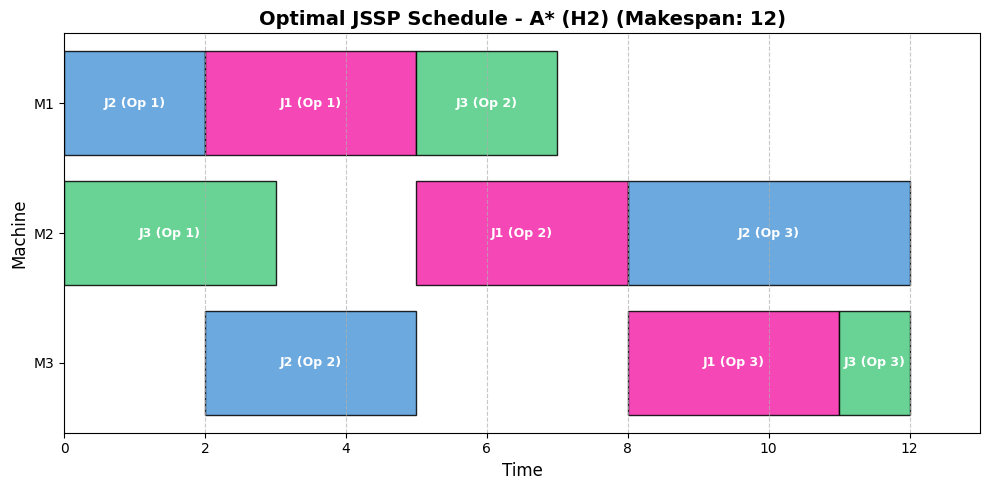

In [ ]:
import matplotlib.pyplot as plt
import os

# 1. Collect all evaluated algorithms
algorithms = [
    {
        'name': 'DFS',
        'makespan': optimal_makespan_dfs,
        'time': time_dfs,
        'schedule': optimal_schedule_dfs
    },
    {
        'name': 'A* (H1)',
        'makespan': optimal_makespan_h1,
        'time': time_h1,
        'schedule': optimal_schedule_h1
    },
    {
        'name': 'A* (H2)',
        'makespan': optimal_makespan_h2,
        'time': time_h2,
        'schedule': optimal_schedule_h2
    },
    {
        'name': 'Multi-Start Hill-Climbing',
        'makespan': optimal_makespan_hc,
        'time': time_hc,
        'schedule': optimal_schedule_hc
    }
]

# 2. Select the best result (Criteria: Lowest makespan, tie-breaker: Lowest execution time)
best_algorithm = min(algorithms, key=lambda x: (x['makespan'], x['time']))

print("=== BEST SOLUTION EVALUATION ===")
print(f"Best Algorithm: {best_algorithm['name']}")
print(f"Best Makespan: {best_algorithm['makespan']}")
print(f"Execution Time: {best_algorithm['time']:.4f} seconds\n")

# 3. Color mapping for Gantt chart visualization
job_colors = {
    'J1': '#F527A9',  # Pink
    'J2': '#529AD9',  # Blue
    'J3': '#4ECC81'   # Green
}

# 4. Generate Gantt diagram for the overall best solution found
if best_algorithm['schedule']:
    fig, ax = plt.subplots(figsize=(10, 5))

    for item in best_algorithm['schedule']:
        machine = item['Machine']
        label = item['Label']
        start = item['Initial time']
        duration = item['Duration']

        # Extract Job ID (e.g., 'J1' from 'J1 (Op 1)')
        job_id = label.split()[0]
        color = job_colors.get(job_id, '#333333')

        ax.barh(machine, duration, left=start, color=color, edgecolor='black', alpha=0.85)
        ax.text(start + duration / 2, machine, label,
                ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    # Figure styling
    ax.set_xlabel('Time', fontsize=12)
    ax.set_ylabel('Machine', fontsize=12)
    ax.set_title(f"Optimal JSSP Schedule - {best_algorithm['name']} (Makespan: {best_algorithm['makespan']})",
                 fontsize=14, fontweight='bold')

    ax.invert_yaxis()  # M1 on top, M3 on bottom
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    ax.set_xlim(0, best_algorithm['makespan'] + 1)

    plt.tight_layout()

    # Save final Gantt chart
    os.makedirs('results', exist_ok=True)
    plt.savefig('results/Best solution_JSSP_Gantt_Chart.png', dpi=300, bbox_inches='tight')
    print("Best Gantt chart solution successfully saved in: results/Best_JSSP_Gantt_Chart.png")

    plt.show()
else:
    print("No valid schedule was found to plot.")